In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

df = pd.read_csv("irrigation_prediction.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (10000, 20)

First five rows:
  Soil_Type  Soil_pH  Soil_Moisture  Organic_Carbon  Electrical_Conductivity  \
0      Clay     6.14          36.48            0.42                     2.17   
1      Silt     6.41          50.56            0.38                     0.23   
2     Sandy     7.71          40.07            1.09                     2.18   
3      Clay     5.96          12.75            1.56                     0.40   
4      Clay     7.76          18.58            0.95                     2.52   

   Temperature_C  Humidity  Rainfall_mm  Sunlight_Hours  Wind_Speed_kmh  \
0          21.90     31.19      1167.70            4.01            1.97   
1          36.50     26.01       831.28           10.72           16.82   
2          41.83     76.41      1844.45            7.75           19.03   
3          37.22     43.32       306.26            8.90           11.44   
4          22.38     86.44      1875.63           10.39           11.26   

  Crop_Type Crop_Growth

In [ ]:

def simple_linear_regression(x, y):
    x_mean = np.mean(x)
    y_mean = np.mean(y)

    numerator = np.sum((x - x_mean) * (y - y_mean))
    denominator = np.sum((x - x_mean) ** 2)

    if denominator == 0:
        raise ValueError("Independent variable has no variation.")

    w1 = numerator / denominator
    w0 = y_mean - w1 * x_mean

    return w0, w1


def multiple_linear_regression(X, y):
    X_with_intercept = np.column_stack(
        (np.ones(len(X)), X)
    )

    coefficients = (
        np.linalg.pinv(X_with_intercept.T @ X_with_intercept)
        @ X_with_intercept.T
        @ y
    )

    return coefficients


print("Regression functions defined successfully!")

Regression functions defined successfully!


In [ ]:

target = "Soil_Moisture"

simple_features = ["Rainfall_mm"]

multiple_features = [
    "Rainfall_mm",
    "Humidity",
    "Temperature_C",
    "Sunlight_Hours",
    "Previous_Irrigation_mm",
    "Organic_Carbon",
    "Soil_pH"
]

required_columns = list(dict.fromkeys(
    [target] + simple_features + multiple_features
))

data = df[required_columns].dropna().reset_index(drop=True)

original_y = data[target].to_numpy(dtype=float)

rng = np.random.default_rng(42)
indices = rng.permutation(len(data))

n_test = int(0.20 * len(data))
test_indices = indices[:n_test]
train_indices = indices[n_test:]

print("Total usable rows:", len(data))
print("Training rows:", len(train_indices))
print("Artificially missing values:", len(test_indices))

Total usable rows: 10000
Training rows: 8000
Artificially missing values: 2000


In [ ]:

x = data["Rainfall_mm"].to_numpy(dtype=float)
y = original_y

w0, w1 = simple_linear_regression(
    x[train_indices],
    y[train_indices]
)

simple_predictions = w0 + w1 * x[test_indices]

print("Simple Linear Regression")
print("Intercept (w0):", w0)
print("Slope (w1):", w1)
print("\nFirst 10 actual values:")
print(y[test_indices][:10])
print("\nFirst 10 predicted values:")
print(simple_predictions[:10])

Simple Linear Regression
Intercept (w0): 37.043496176794235
Slope (w1): -0.00010276200296196249

First 10 actual values:
[15.64 39.49 50.08 49.11 36.25 46.23 43.36 10.83 33.03 22.19]

First 10 predicted values:
[36.80643554 37.01963792 37.01805847 36.96872963 37.00564277 36.83839041
 37.01313925 36.88047762 36.86220962 36.98174752]


In [ ]:

X = data[multiple_features].to_numpy(dtype=float)
y = original_y

coefficients = multiple_linear_regression(
    X[train_indices],
    y[train_indices]
)

X_test_with_intercept = np.column_stack(
    (np.ones(len(test_indices)), X[test_indices])
)

multiple_predictions = X_test_with_intercept @ coefficients

print("Multiple Linear Regression")
print("Intercept:", coefficients[0])
print("Coefficients:", coefficients[1:])
print("\nFirst 10 actual values:")
print(y[test_indices][:10])
print("\nFirst 10 predicted values:")
print(multiple_predictions[:10])

Multiple Linear Regression
Intercept: 38.740673713646295
Coefficients: [-1.00857761e-04 -8.27777920e-04 -2.04590911e-02  1.41742217e-01
 -3.02778218e-03 -7.59765333e-01 -1.95070373e-01]

First 10 actual values:
[15.64 39.49 50.08 49.11 36.25 46.23 43.36 10.83 33.03 22.19]

First 10 predicted values:
[37.34503513 36.82974795 37.0880301  37.25631137 36.77530763 37.33587563
 36.76476287 37.08991189 37.23814765 36.71616515]


In [ ]:

def evaluate_model(actual, predicted):
    errors = actual - predicted

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    ss_res = np.sum(errors ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)

    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else float("nan")

    return mae, rmse, r2


actual = original_y[test_indices]

simple_metrics = evaluate_model(actual, simple_predictions)
multiple_metrics = evaluate_model(actual, multiple_predictions)

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Simple Linear Regression": simple_metrics,
    "Multiple Linear Regression": multiple_metrics
})

print(results.to_string(index=False))

  Metric  Simple Linear Regression  Multiple Linear Regression
     MAE                 14.186492                   14.184665
    RMSE                 16.419401                   16.416648
R2 Score                 -0.000194                    0.000141


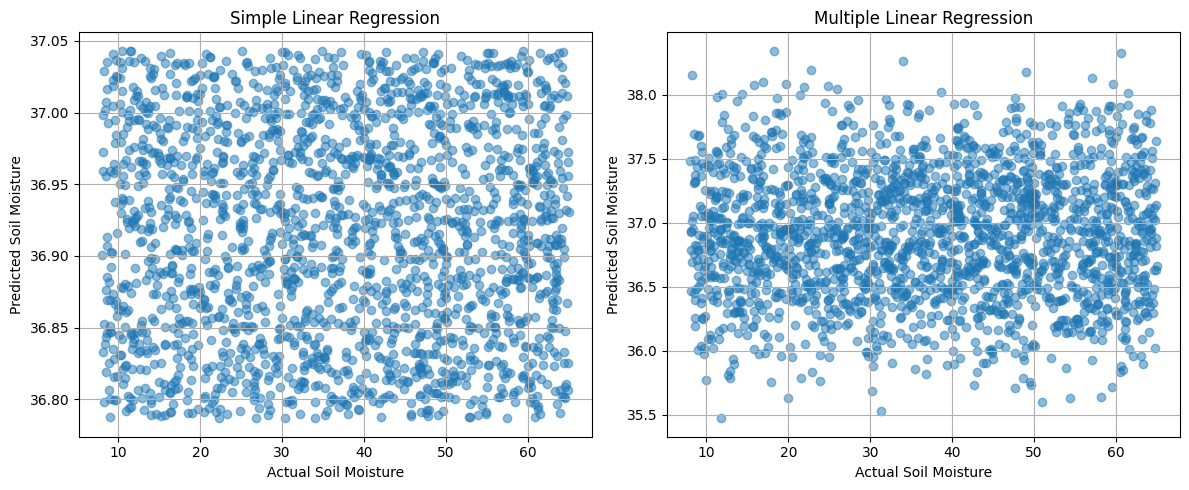

In [ ]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(actual, simple_predictions, alpha=0.5)
plt.xlabel("Actual Soil Moisture")
plt.ylabel("Predicted Soil Moisture")
plt.title("Simple Linear Regression")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(actual, multiple_predictions, alpha=0.5)
plt.xlabel("Actual Soil Moisture")
plt.ylabel("Predicted Soil Moisture")
plt.title("Multiple Linear Regression")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:

original_df = pd.read_csv("irrigation_prediction.csv")

missing_mask = original_df["Soil_Moisture"].isna()

print("Actual missing Soil_Moisture values:",
      missing_mask.sum())

if missing_mask.any():
    simple_train = original_df[
        original_df["Soil_Moisture"].notna()
        & original_df["Rainfall_mm"].notna()
    ]

    if len(simple_train) >= 2:
        w0, w1 = simple_linear_regression(
            simple_train["Rainfall_mm"].to_numpy(dtype=float),
            simple_train["Soil_Moisture"].to_numpy(dtype=float)
        )

        simple_rows = (
            missing_mask
            & original_df["Rainfall_mm"].notna()
        )

        original_df.loc[simple_rows, "Soil_Moisture"] = (
            w0 * 1
            + w1 * original_df.loc[simple_rows, "Rainfall_mm"]
        )

    print("Predictions filled wherever the simple model had inputs.")

    original_df.to_csv(
        "irrigation_prediction_filled.csv",
        index=False
    )
    print("Saved as irrigation_prediction_filled.csv")
else:
    print("No actual missing values exist in this column.")
    print("The artificial missing-value experiment above demonstrates imputation.")

Actual missing Soil_Moisture values: 0
No actual missing values exist in this column.
The artificial missing-value experiment above demonstrates imputation.
